# Notebook 2: how alike are two levels, as a function of the distance between them?

Reads `outputs/measurements.csv` from notebook 1.

**Question.** For the same 1 mm of tissue, how different are two levels `h` µm apart? If the difference stays small, nearby levels largely repeat each other.

**Variogram.** For every pair of levels `h` apart, square the difference in gland space and average:

  **γ(h) = ½ × mean of (value at depth z+h − value at depth z)²**

γ starts low for neighbouring levels and rises with distance. Where it levels off (the *sill*) is the distance beyond which levels are effectively unrelated. The method comes from geostatistics and is standard in stereology for judging systematic sections.

**Why not plain correlation.** Correlation subtracts each window's mean first. With only 33 levels over 160 µm, that forces the top and bottom of a stack to look opposite and biases correlation downwards at long distances, making levels look less alike than they are. The variogram uses only differences, so it needs no mean.

windows: 132 in total, 8 dropped for missing depths, 16 dropped for too few glands, 108 kept
kept per core: {'PRD_P000_A': 10, 'PRD_P000_B': 6, 'PRD_P000_C1': 12, 'PRD_P000_C2': 12, 'PRD_P000_D1': 10, 'PRD_P001_B': 9, 'PRD_P001_D1': 7, 'PRD_P001_E': 9, 'PRD_P001_F2': 9, 'PRD_P002_A': 10, 'PRD_P002_B': 8, 'PRD_P002_F': 6}


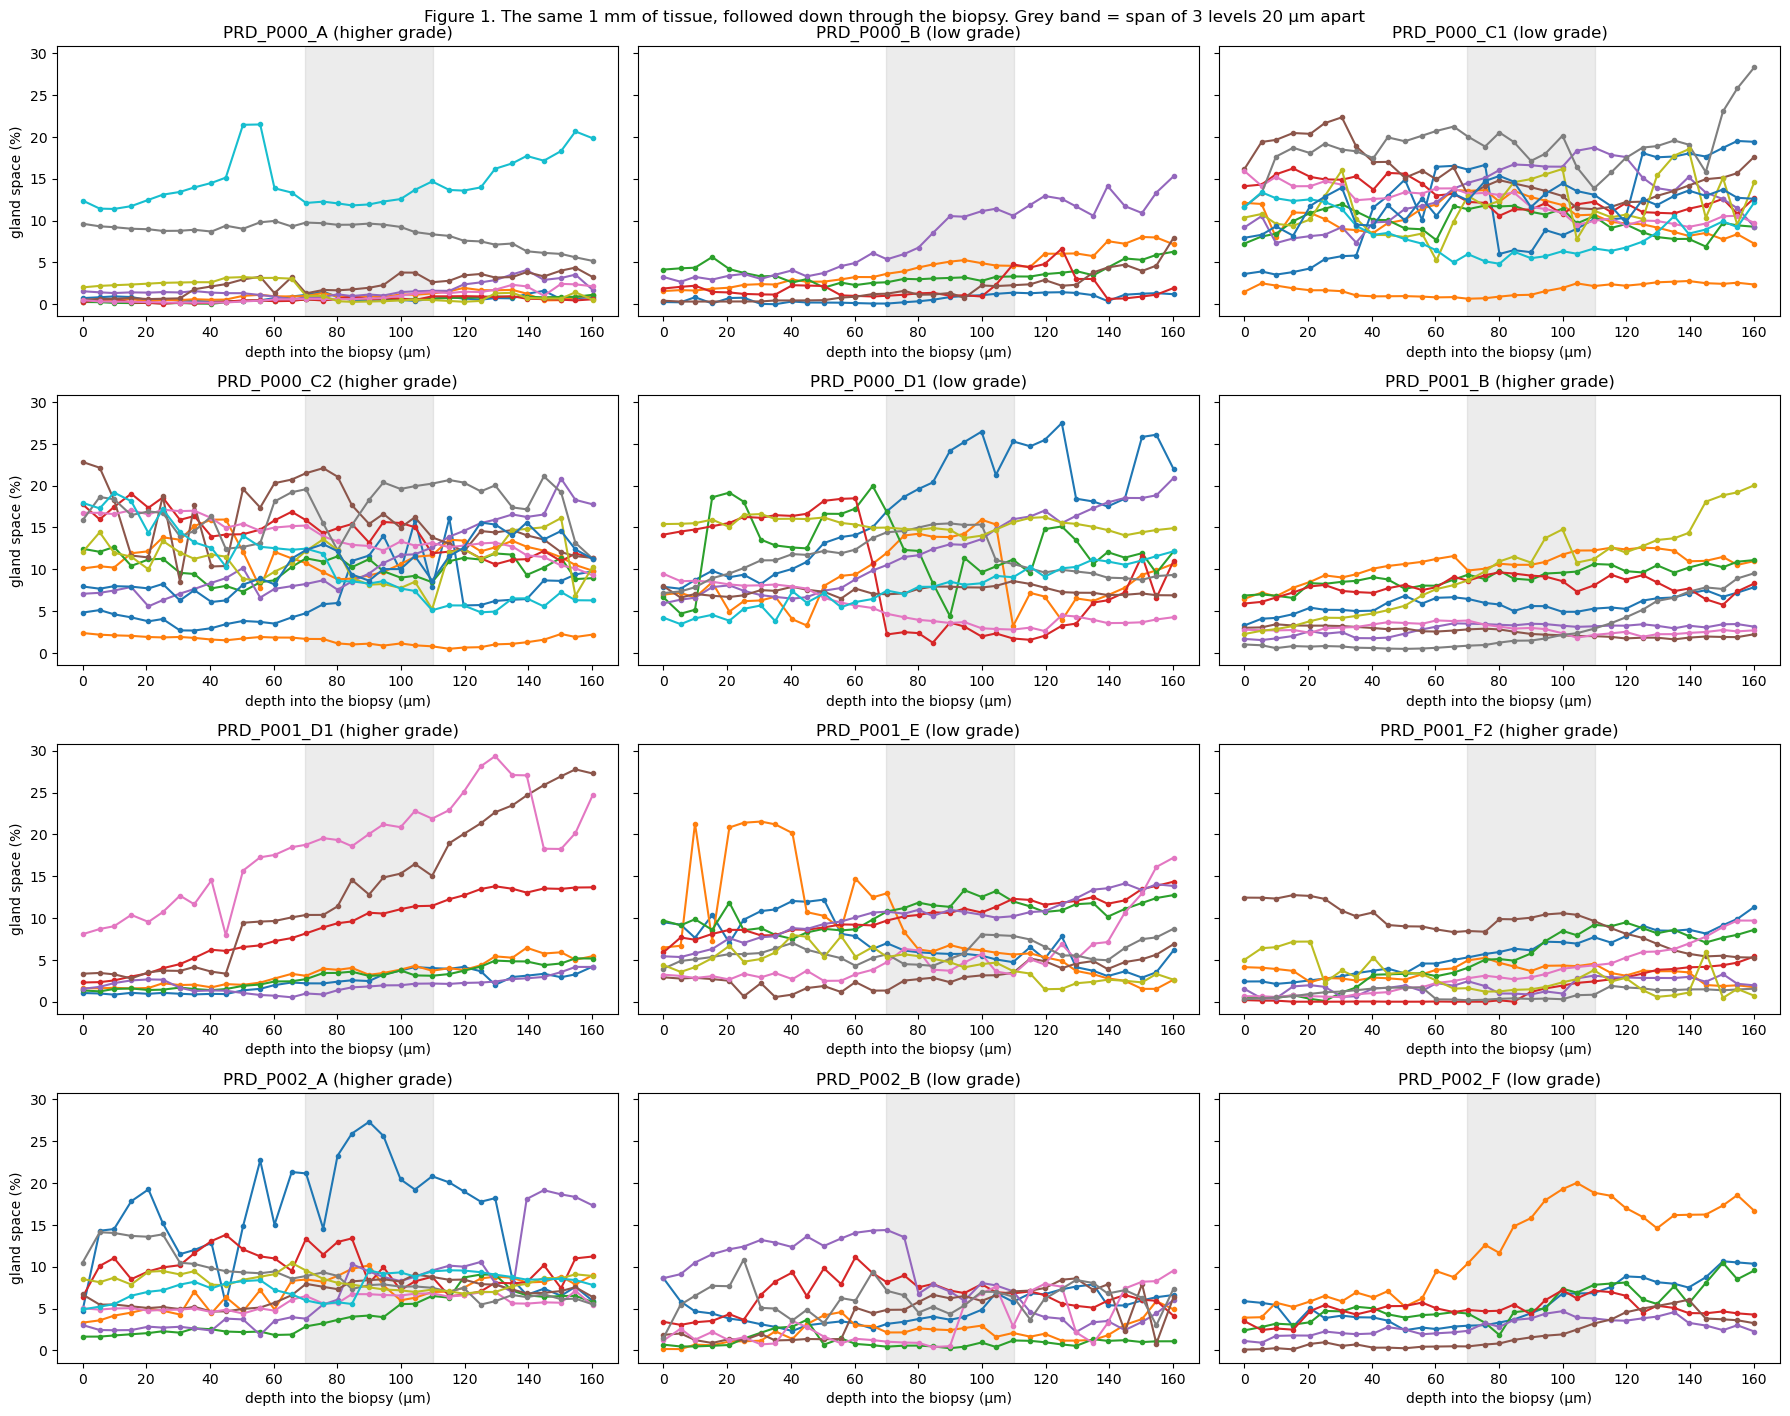

                   mean %  min %  max %  max ÷ min
core       window                                 
PRD_P000_A 0         0.71   0.32   1.60       5.06
           1         0.94   0.32   1.95       6.05
           2         0.53   0.05   1.12      22.44
           4         0.54   0.06   0.96      16.39
           5         1.73   0.57   4.08       7.17
...                   ...    ...    ...        ...
PRD_P002_F 2        12.00   3.92  20.03       5.11
           3         5.44   1.84  10.46       5.69
           4         4.92   2.44   7.21       2.95
           5         2.83   0.93   4.70       5.07
           6         1.97   0.10   6.07      60.10

[108 rows x 4 columns]


In [1]:
# ============================================================
# STEP 8: LOAD THE TABLE AND PLOT DEPTH PROFILES
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit      # fits a formula to data by least squares

OUT_DIR = Path.cwd() / "outputs"
table = pd.read_csv(OUT_DIR / "measurements.csv").sort_values(["core", "window", "depth_um"])

# ---- Settings ----------------------------------------------------
MIN_MEAN_LUMEN = 0.005   # ignore windows averaging under 0.5% gland space: almost no glands, so changes are just blips
STEP_UM        = 5.0     # spacing between slices in the stack (about 5 µm)
MAX_LAG        = 16      # only trust gaps up to 16 slices = 80 µm, half the stack (fewer pairs at bigger gaps)

# Rule 1: keep only windows measured at EVERY depth.
# A window at the ragged end of a core can drop in and out between slices (step 6 of notebook 1 skips windows
# with under 25% tissue). Then "k slices apart" would no longer mean "k x 5 µm apart", so those windows go.
n_depths = table["depth_um"].nunique()                                   # 33 slices per core
slices_per_window = table.groupby(["core", "window"])["depth_um"].transform("count")
complete = table[slices_per_window == n_depths]

# Rule 2: keep only windows with enough glands to be worth studying.
win_mean = complete.groupby(["core", "window"])["lumen_frac"].transform("mean")
used = complete[win_mean >= MIN_MEAN_LUMEN]

n_all = table.groupby(["core", "window"]).ngroups
n_complete = complete.groupby(["core", "window"]).ngroups
n_used = used.groupby(["core", "window"]).ngroups
print(f"windows: {n_all} in total, {n_all - n_complete} dropped for missing depths, "
      f"{n_complete - n_used} dropped for too few glands, {n_used} kept")
print("kept per core:", used.groupby("core")["window"].nunique().to_dict())

# FIGURE 1: lumen fraction against depth, one line per window.
# Each line is the same 1 mm of tissue, followed 160 µm down into the biopsy.
n_cores = used["core"].nunique()
ncols = 3 if n_cores > 2 else n_cores                    # 3 panels per row once there are more than 2 cores
nrows = int(np.ceil(n_cores / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows), sharey=True, squeeze=False)
ax = ax.ravel()
for a in ax[n_cores:]:
    a.axis("off")                                        # hide spare panels
for a, (core, sub) in zip(ax, used.groupby("core")):
    for w, g in sub.groupby("window"):
        a.plot(g["depth_um"], 100 * g["lumen_frac"], marker=".", label=f"window {w}")
    a.set_title(f"{core} ({sub['grade'].iloc[0]})")
    a.set_xlabel("depth into the biopsy (µm)")
    a.axvspan(70, 110, color="grey", alpha=0.15)     # grey band: where 3 guideline levels 20 µm apart would sit (one example)
for a in ax[::ncols]:
    a.set_ylabel("gland space (%)")
fig.suptitle("Figure 1. The same 1 mm of tissue, followed down through the biopsy. Grey band = span of 3 levels 20 µm apart")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig1_depth_profiles.png", dpi=130)
plt.show()

# How much does each window change over 160 µm?
g = used.groupby(["core", "window"])["lumen_frac"]
summary = pd.DataFrame({"mean %": 100 * g.mean(), "min %": 100 * g.min(), "max %": 100 * g.max()})
summary["max ÷ min"] = summary["max %"] / summary["min %"].replace(0, np.nan)
print(summary.round(2))

**Result.** 132 windows: 8 dropped for missing depths, 16 for averaging under 0.5% gland space, **108 kept** (6 to 12 per core).

**Figure 1.** Each line is one 1 mm window followed through 160 µm. Inside the grey band (the span of three levels 20 µm apart) most lines barely move; across the full depth many change substantially, for example rising from about 8% to 29% (`PRD_P001_D1`). Steady trends reflect cutting through gland tubes at different points; abrupt steps that plateau and return are more likely segmentation changes.

**Table.** `max ÷ min` is the fold change of each window over 160 µm: a median of 2.7-fold (typically 1.9 to 5) for windows with at least 5% gland space, and about 11-fold for sparse windows.

Windows with gaps in depth are removed so that a gap of `k` levels always means `k` x 5 µm.

## Step 9: Build the variogram

For each window, γ(h) is computed for gaps of 1 to 16 levels (5 to 80 µm) and divided by that window's variance, so gland-rich and gland-poor windows count equally. The normalised curves are averaged over all windows. Gaps are limited to half the stack (80 µm), where enough pairs remain for a stable estimate.

In [2]:
# ============================================================
# STEP 9: THE VARIOGRAM
# ============================================================

def window_variogram(x):
    # x = lumen fraction down the stack for ONE window (33 values, top to bottom)
    spread = x.var(ddof=1)                                   # this window's variance, used only to rescale
    gammas = []
    for k in range(1, MAX_LAG + 1):                          # k = gap in slices
        diffs = x[k:] - x[:-k]                               # every pair of slices k apart
        gammas.append(0.5 * np.mean(diffs ** 2) / spread)    # ½ × average squared difference, rescaled
    return np.array(gammas)

series = [g["lumen_frac"].values for _, g in used.groupby(["core", "window"])]   # one array per window
h = np.arange(1, MAX_LAG + 1) * STEP_UM                                           # gaps in µm: 5, 10, ... 80

all_curves = np.array([window_variogram(x) for x in series])   # one row per window
pooled = all_curves.mean(axis=0)                                # average curve

for hh, gg in zip(h, pooled):
    print(f"gap {hh:4.0f} µm   γ = {gg:.2f}")

gap    5 µm   γ = 0.17
gap   10 µm   γ = 0.27
gap   15 µm   γ = 0.39
gap   20 µm   γ = 0.49
gap   25 µm   γ = 0.58
gap   30 µm   γ = 0.66
gap   35 µm   γ = 0.74
gap   40 µm   γ = 0.82
gap   45 µm   γ = 0.88
gap   50 µm   γ = 0.94
gap   55 µm   γ = 1.01
gap   60 µm   γ = 1.07
gap   65 µm   γ = 1.14
gap   70 µm   γ = 1.20
gap   75 µm   γ = 1.27
gap   80 µm   γ = 1.34


**Result.** γ rises steadily from 0.17 at 5 µm to 1.34 at 80 µm, without levelling off. Levels 20 µm apart differ about a third as much as levels 80 µm apart (0.49 ÷ 1.34 = 0.37). A γ near 1 means as different as a typical pair of levels in that window.

## Step 10: Fit nugget, sill and correlation length

Exponential variogram with a nugget:

  **γ(h) = nugget + (sill − nugget) × (1 − e^(−h / L))**

* **nugget:** the value at zero distance, i.e. measurement noise, since levels a hair apart should be identical;
* **sill:** the plateau, where levels are unrelated;
* **L:** correlation length; levels L apart are about 37% alike under the model.

Because the curve is still rising at 80 µm, the sill and L are only weakly identified: a high sill with a long L and a lower sill with a shorter L fit the visible range equally well. L is therefore treated as a rough guide, and step 11 uses a quantity that doesn't depend on the sill.

nugget (noise)      = 0.07  -> 3% of the total variation is measurement noise
sill                = 2.45
correlation length L = 108 µm


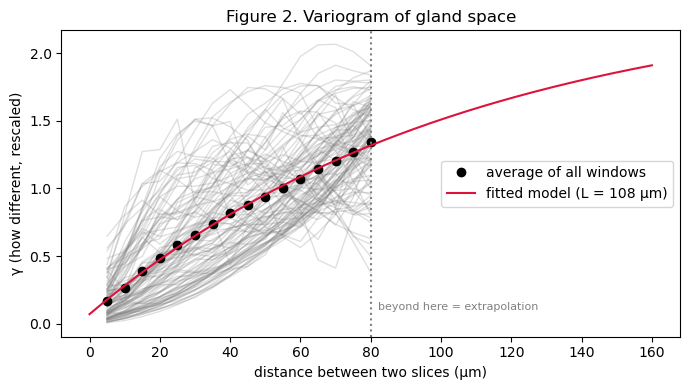

In [3]:
# ============================================================
# STEP 10: FIT NUGGET, SILL AND CORRELATION LENGTH
# ============================================================

def model(h, nugget, sill, L):
    return nugget + (sill - nugget) * (1 - np.exp(-h / L))

# curve_fit tries values of (nugget, sill, L) until the model curve is as close as possible to the data.
# bounds keep the numbers physically sensible (no negative noise, L between 1 and 500 µm).
BOUNDS = ([0, 0.1, 1], [2, 3, 500])
(nugget, sill, L), _ = curve_fit(model, h, pooled, p0=[0.2, 1, 30], bounds=BOUNDS)

print(f"nugget (noise)      = {nugget:.2f}  -> {nugget / sill:.0%} of the total variation is measurement noise")
print(f"sill                = {sill:.2f}")
print(f"correlation length L = {L:.0f} µm")
if sill > 0.95 * BOUNDS[1][1]:
    print("WARNING: the sill hit its upper limit. The curve hasn't levelled off, so L is a rough guide only.")

# FIGURE 2: the variogram and the fitted model
hh = np.linspace(0, 160, 200)
plt.figure(figsize=(7, 4))
for c in all_curves:
    plt.plot(h, c, color="grey", alpha=0.25, lw=1)                 # each window, faint
plt.plot(h, pooled, "o", color="black", label="average of all windows")
plt.plot(hh, model(hh, nugget, sill, L), color="crimson", label=f"fitted model (L = {L:.0f} µm)")
plt.axvline(80, ls=":", color="grey"); plt.text(82, 0.1, "beyond here = extrapolation", fontsize=8, color="grey")
plt.xlabel("distance between two slices (µm)")
plt.ylabel("γ (how different, rescaled)")
plt.title("Figure 2. Variogram of gland space")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "fig2_variogram.png", dpi=130)
plt.show()

**Result.** Nugget 0.07, sill 2.45, L = 108 µm. Measurement noise is 0.07 ÷ 2.45 ≈ **3%** of the variation, so the changes with depth are tissue, not measurement. In Figure 2 the model passes through the pooled points; beyond the dotted line at 80 µm it is extrapolation.

## Step 11: Independent looks from three levels

For n levels with pairwise correlations ρ, the effective number of independent looks is

  **n_eff = n² ÷ (sum of all pairwise correlations, including each level with itself)**

so three identical levels give 1 and three unrelated levels give 3.

**(a) Upper limit from the data alone.** The sill is at least γ(80), because the curve is still rising. Setting the sill to γ(80) makes every correlation as small as the data allows, ρ(h) ≥ 1 − γ(h) / γ(80), and therefore gives the largest possible n_eff. This holds wherever the curve eventually levels off. Measurement noise only lowers correlations further, so the bound remains an upper limit.

**(b) Model estimate.** Uses ρ(h) = e^(−h/L) from step 10, so it depends on the weakly identified L.

In [4]:
# ============================================================
# STEP 11: EFFECTIVE NUMBER OF LOOKS
# ============================================================

def n_eff_general(positions_um, rho):
    # rho(d) = correlation between two slides d µm apart. Sum it over every pair, self-pairs included.
    n = len(positions_um)
    total = sum(1.0 if a == b else rho(abs(a - b)) for a in positions_um for b in positions_um)
    return n ** 2 / total

def rho_bound_from(curve):
    # (a) data-only bound: rho(d) >= 1 - gamma(d) / gamma(80)
    g80 = curve[-1]                                       # last point = gap of 80 µm
    def rho(d):
        k = int(round(d / STEP_UM))                       # gap in slices
        return max(0.0, 1 - curve[k - 1] / g80)           # curve[0] is the 5 µm gap
    return rho

def n_eff(positions_um, L):
    # (b) model's best guess, using e^(-d/L)
    return n_eff_general(positions_um, lambda d: np.exp(-d / L))

rho_bound = rho_bound_from(pooled)
print("(a) UPPER LIMIT from the data alone:")
for name, pos in {"3 levels 5 µm apart": [0, 5, 10],
                  "3 levels 20 µm apart (guideline)": [0, 20, 40],
                  "3 levels 40 µm apart": [0, 40, 80]}.items():
    print(f"   {name:36s} -> at most {n_eff_general(pos, rho_bound):.2f} independent looks")

print("\n(b) MODEL'S BEST GUESS (relies on L, see the warning in step 10):")
for name, pos in {"3 levels 5 µm apart": [0, 5, 10],
                  "3 levels 20 µm apart (guideline)": [0, 20, 40],
                  "3 levels 40 µm apart": [0, 40, 80],
                  "3 levels 80 µm apart (EXTRAPOLATED)": [0, 80, 160],
                  "3 levels across 1 mm (EXTRAPOLATED)": [0, 450, 900]}.items():
    print(f"   {name:36s} -> about {n_eff(pos, L):.2f} independent looks")

(a) UPPER LIMIT from the data alone:
   3 levels 5 µm apart                  -> at most 1.11 independent looks
   3 levels 20 µm apart (guideline)     -> at most 1.42 independent looks
   3 levels 40 µm apart                 -> at most 1.97 independent looks

(b) MODEL'S BEST GUESS (relies on L, see the warning in step 10):
   3 levels 5 µm apart                  -> about 1.04 independent looks
   3 levels 20 µm apart (guideline)     -> about 1.17 independent looks
   3 levels 40 µm apart                 -> about 1.34 independent looks
   3 levels 80 µm apart (EXTRAPOLATED)  -> about 1.68 independent looks
   3 levels across 1 mm (EXTRAPOLATED)  -> about 2.94 independent looks


**Result.** Upper limits: three levels 5 µm apart, **1.11**; 20 µm apart, **1.42**; 40 µm apart, **1.97**. Model estimates are lower (1.04, 1.17, 1.34), as they must be.

Worked check from step 9: ρ(20) ≥ 1 − 0.49/1.34 = 0.63 and ρ(40) ≥ 1 − 0.82/1.34 = 0.39; the sum of pairwise correlations for levels at 0, 20 and 40 µm is 3 + 2 × (0.63 + 0.63 + 0.39) = 6.30, and 9 ÷ 6.30 = 1.43, matching 1.42 up to rounding.

Three levels about 20 µm apart therefore represent at most about 1.4 independent views of gland structure. This describes how much the levels repeat each other for an averaged measure; it is not a rate of missed or misgraded cancer.

## Step 12: Uncertainty (cluster bootstrap)

Whole cores are resampled with replacement 1,000 times, and the variogram, fit and bound are recomputed each time. Windows from the same core share a patient, needle, stain and imaging run, so resampling windows individually would understate the uncertainty. The 12 cores come from 3 patients, so these ranges are still somewhat optimistic.

In [5]:
# ============================================================
# STEP 12: BOOTSTRAP UNCERTAINTY
# ============================================================
rng = np.random.default_rng(0)              # fixed seed so results are reproducible
core_of_window = [core for (core, w), _ in used.groupby(["core", "window"])]   # which core each curve came from
cores = sorted(set(core_of_window))
by_core = {c: all_curves[[i for i, k in enumerate(core_of_window) if k == c]] for c in cores}
cluster = len(cores) >= 5
print("resampling", "CORES (cluster bootstrap)" if cluster else "WINDOWS (too few cores to resample cores)")

Ls, noise_share, looks_20, bound_20 = [], [], [], []
for _ in range(1000):
    if cluster:
        picked = rng.choice(cores, size=len(cores), replace=True)            # random cores, with replacement
        curve = np.vstack([by_core[c] for c in picked]).mean(axis=0)          # all windows of the picked cores
    else:
        pick = rng.integers(0, len(all_curves), len(all_curves))             # random windows, with replacement
        curve = all_curves[pick].mean(axis=0)
    try:
        (nu, si, LL), _ = curve_fit(model, h, curve, p0=[nugget, sill, L], bounds=BOUNDS, maxfev=5000)
    except RuntimeError:
        continue                                                   # skip the rare resample that won't fit
    Ls.append(LL); noise_share.append(nu / si); looks_20.append(n_eff([0, 20, 40], LL))
    bound_20.append(n_eff_general([0, 20, 40], rho_bound_from(curve)))

def middle90(a): return np.percentile(a, [5, 50, 95])
print("correlation length L (µm):            5% {:.0f} | median {:.0f} | 95% {:.0f}".format(*middle90(Ls)))
print("noise share of variation:             5% {:.0%} | median {:.0%} | 95% {:.0%}".format(*middle90(noise_share)))
print("UPPER LIMIT, 3 levels 20 µm apart:     5% {:.2f} | median {:.2f} | 95% {:.2f}".format(*middle90(bound_20)))
print("model guess, 3 levels 20 µm apart:     5% {:.2f} | median {:.2f} | 95% {:.2f}".format(*middle90(looks_20)))

# Each core on its own: do they agree?
# (a core with only 1 or 2 usable windows gives a shaky fit, so read these as rough)
for core, sub in used.groupby("core"):
    curves = np.array([window_variogram(g["lumen_frac"].values) for _, g in sub.groupby("window")])
    try:
        (nu, si, LL), _ = curve_fit(model, h, curves.mean(axis=0), p0=[nugget, sill, L], bounds=BOUNDS, maxfev=5000)
        print(f"{core} ({sub['grade'].iloc[0]}): {len(curves)} windows, L ≈ {LL:.0f} µm, noise share {nu / si:.0%}")
    except RuntimeError:
        print(f"{core}: {len(curves)} windows, fit failed")

resampling CORES (cluster bootstrap)
correlation length L (µm):            5% 70 | median 111 | 95% 147
noise share of variation:             5% 1% | median 3% | 95% 5%
UPPER LIMIT, 3 levels 20 µm apart:     5% 1.36 | median 1.42 | 95% 1.48
model guess, 3 levels 20 µm apart:     5% 1.12 | median 1.16 | 95% 1.26
PRD_P000_A (higher grade): 10 windows, L ≈ 75 µm, noise share 4%
PRD_P000_B (low grade): 6 windows, L ≈ 150 µm, noise share 1%
PRD_P000_C1 (low grade): 12 windows, L ≈ 72 µm, noise share 2%
PRD_P000_C2 (higher grade): 12 windows, L ≈ 28 µm, noise share 4%
PRD_P000_D1 (low grade): 10 windows, L ≈ 63 µm, noise share 0%
PRD_P001_B (higher grade): 9 windows, L ≈ 139 µm, noise share 0%
PRD_P001_D1 (higher grade): 7 windows, L ≈ 166 µm, noise share 0%
PRD_P001_E (low grade): 9 windows, L ≈ 164 µm, noise share 2%
PRD_P001_F2 (higher grade): 9 windows, L ≈ 80 µm, noise share 0%
PRD_P002_A (higher grade): 10 windows, L ≈ 94 µm, noise share 2%
PRD_P002_B (low grade): 8 windows, L ≈ 54 µm,

**Result** (5% | median | 95%):

* upper limit, three levels 20 µm apart: **1.36 | 1.42 | 1.48**
* noise share: 1% | 3% | 5%
* model estimate at 20 µm: 1.12 | 1.16 | 1.26
* L: 70 | 111 | 147 µm, much less certain than the bound

Per-core correlation lengths range from about 28 µm (`PRD_P000_C2`) to 166 µm (`PRD_P001_D1`): individual biopsies differ considerably in how fast their architecture changes. Each bootstrap median agrees with the main estimate.

## Step 13: Higher grade versus low grade

Windows are split by each core's grade label, and the upper limit on looks for three levels 20 µm apart is computed per group with the cluster bootstrap. A higher limit would mean faster change with depth. The bound is used instead of L because L is weakly identified.

low grade   : 6 cores, 3 levels 20 µm apart -> at most 1.43 looks (90% range 1.37 to 1.49); gamma(20)/gamma(80) = 0.38
higher grade: 6 cores, 3 levels 20 µm apart -> at most 1.41 looks (90% range 1.31 to 1.51); gamma(20)/gamma(80) = 0.35


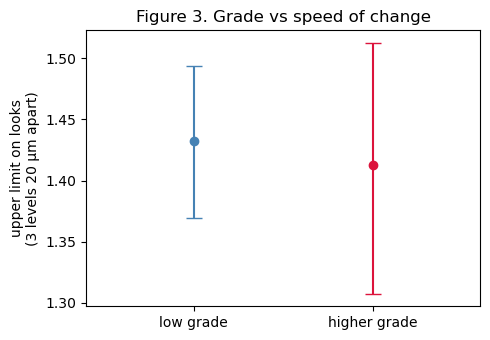

In [6]:
# ============================================================
# STEP 13: HIGHER GRADE VERSUS LOW GRADE
# ============================================================
grade_of_core = used.groupby("core")["grade"].first().to_dict()
results = {}
for grade in ["low grade", "higher grade"]:
    g_cores = [c for c in cores if grade_of_core[c] == grade]
    if len(g_cores) == 0:
        continue
    curve_g = np.vstack([by_core[c] for c in g_cores]).mean(axis=0)
    est = n_eff_general([0, 20, 40], rho_bound_from(curve_g))
    boots = []
    for _ in range(1000):
        picked = rng.choice(g_cores, size=len(g_cores), replace=True)          # cluster bootstrap within the group
        boots.append(n_eff_general([0, 20, 40], rho_bound_from(np.vstack([by_core[c] for c in picked]).mean(axis=0))))
    lo, hi = np.percentile(boots, [5, 95])
    results[grade] = (est, lo, hi)
    print(f"{grade:12s}: {len(g_cores)} cores, 3 levels 20 µm apart -> at most {est:.2f} looks "
          f"(90% range {lo:.2f} to {hi:.2f}); gamma(20)/gamma(80) = {curve_g[3] / curve_g[-1]:.2f}")

# FIGURE 3: the two groups side by side
plt.figure(figsize=(5, 3.5))
for k, (grade, (est, lo, hi)) in enumerate(results.items()):
    plt.errorbar(k, est, yerr=[[max(est - lo, 0)], [max(hi - est, 0)]], fmt="o", capsize=6,
                 color=["steelblue", "crimson"][k])
plt.xticks(range(len(results)), list(results.keys()))
plt.ylabel("upper limit on looks\n(3 levels 20 µm apart)")
plt.title("Figure 3. Grade vs speed of change")
plt.xlim(-0.6, len(results) - 0.4)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig3_grade.png", dpi=130)
plt.show()

**Result.** Low grade: at most 1.43 looks (1.37 to 1.49). Higher grade: at most 1.41 (1.31 to 1.51). γ(20)/γ(80) is 0.38 and 0.35. The ranges overlap almost completely, so **no difference is detectable** with 6 cores per group; a small real difference can't be ruled out. Variation between individual biopsies is larger than any grade effect seen here.

## Summary

* Measurement noise is about 3% of the variation, so changes in gland space with depth reflect the tissue.
* Three levels about 20 µm apart represent at most about 1.4 independent views of gland structure (90% range 1.36 to 1.48); spacing them 40 µm apart raises this to at most about 2.
* Gland space is still changing at 80 µm, so the full core almost certainly varies more than these 160 µm stacks show.
* No detectable difference between low and higher grade cores.

**Limitations:** gland space is a proxy for architecture, not a grade; 1 mm windows (smaller windows untested); only 160 µm of depth; 3.5 to 4 µm axial resolution makes the smallest gaps look more alike; 12 cores from 3 patients, cut from prostatectomy specimens.